# Praktikum Data Mining: Naive Bayes dan k-Nearest Neighbor
Nama: Auditya Merosya Putri | NIM: 24343001 | Kelompok: 2


In [1]:
import os, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OrdinalEncoder, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.naive_bayes import GaussianNB, CategoricalNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_score, recall_score,
                             f1_score, make_scorer)

# BAGIAN 1. Latihan 1: Perhitungan Manual Naive Bayes

Data 12 mahasiswa (IPK, Kehadiran, Kerja Part-time, Lulus Tepat Waktu).
Pertanyaan: mahasiswa dengan **IPK = Sedang, Kehadiran = Baik, Kerja = Ya** diprediksi lulus tepat waktu atau tidak?

In [2]:
data = [
    ("Tinggi","Baik","Tidak","Ya"), ("Tinggi","Baik","Ya","Ya"),
    ("Tinggi","Kurang","Tidak","Ya"), ("Sedang","Baik","Tidak","Ya"),
    ("Sedang","Baik","Ya","Ya"), ("Sedang","Kurang","Ya","Tidak"),
    ("Sedang","Kurang","Tidak","Tidak"), ("Rendah","Baik","Tidak","Ya"),
    ("Rendah","Kurang","Ya","Tidak"), ("Rendah","Kurang","Tidak","Tidak"),
    ("Tinggi","Kurang","Ya","Tidak"), ("Sedang","Baik","Ya","Tidak"),
]
df = pd.DataFrame(data, columns=["IPK","Kehadiran","Kerja","Lulus"])
print(df)
print()
print(df["Lulus"].value_counts())

       IPK Kehadiran  Kerja  Lulus
0   Tinggi      Baik  Tidak     Ya
1   Tinggi      Baik     Ya     Ya
2   Tinggi    Kurang  Tidak     Ya
3   Sedang      Baik  Tidak     Ya
4   Sedang      Baik     Ya     Ya
5   Sedang    Kurang     Ya  Tidak
6   Sedang    Kurang  Tidak  Tidak
7   Rendah      Baik  Tidak     Ya
8   Rendah    Kurang     Ya  Tidak
9   Rendah    Kurang  Tidak  Tidak
10  Tinggi    Kurang     Ya  Tidak
11  Sedang      Baik     Ya  Tidak

Lulus
Ya       6
Tidak    6
Name: count, dtype: int64


### Langkah 1-3: prior, likelihood, posterior (dihitung dengan fungsi, mengikuti langkah manual)

In [3]:
def nb_manual(df, query, target="Lulus"):
    n = len(df)
    skor = {}
    for kelas in sorted(df[target].unique()):
        sub = df[df[target] == kelas]
        p = len(sub) / n                                   # prior P(C)
        print(f"Kelas {kelas}: prior = {len(sub)}/{n} = {p:.4f}")
        for kol, nilai in query.items():
            lik = (sub[kol] == nilai).mean()               # likelihood P(x|C)
            print(f"   P({kol}={nilai} | {kelas}) = {(sub[kol]==nilai).sum()}/{len(sub)} = {lik:.4f}")
            p *= lik
        skor[kelas] = p
        print(f"   => skor P({kelas}|X) ~ {p:.4f}\n")
    total = sum(skor.values())
    return {k: v / total for k, v in skor.items()}          # normalisasi

q1 = {"IPK": "Sedang", "Kehadiran": "Baik", "Kerja": "Ya"}
post = nb_manual(df, q1)
print("Posterior ternormalisasi:", {str(k): round(float(v), 4) for k, v in post.items()})
print("Prediksi:", max(post, key=post.get))

Kelas Tidak: prior = 6/12 = 0.5000
   P(IPK=Sedang | Tidak) = 3/6 = 0.5000
   P(Kehadiran=Baik | Tidak) = 1/6 = 0.1667
   P(Kerja=Ya | Tidak) = 4/6 = 0.6667
   => skor P(Tidak|X) ~ 0.0278

Kelas Ya: prior = 6/12 = 0.5000
   P(IPK=Sedang | Ya) = 2/6 = 0.3333
   P(Kehadiran=Baik | Ya) = 5/6 = 0.8333
   P(Kerja=Ya | Ya) = 2/6 = 0.3333
   => skor P(Ya|X) ~ 0.0463

Posterior ternormalisasi: {'Tidak': 0.375, 'Ya': 0.625}
Prediksi: Ya


### Langkah 4: Verifikasi dengan scikit-learn (alpha ~ 0 = tanpa smoothing)

In [4]:
enc = OrdinalEncoder()
X = enc.fit_transform(df[["IPK","Kehadiran","Kerja"]])
y = df["Lulus"]

model = CategoricalNB(alpha=1e-10)
model.fit(X, y)
baru = pd.DataFrame([q1])
print("Kelas       :", [str(c) for c in model.classes_])
print("Probabilitas:", model.predict_proba(enc.transform(baru)).round(3))
print("Prediksi    :", model.predict(enc.transform(baru)))

Kelas       : ['Tidak', 'Ya']
Probabilitas: [[0.375 0.625]]
Prediksi    : ['Ya']


### Pertanyaan Diskusi 1a: alpha = 1 (Laplace smoothing)

In [5]:
for a in [1e-10, 1]:
    m = CategoricalNB(alpha=a).fit(X, y)
    print(f"alpha={a:<7} Probabilitas {[str(c) for c in m.classes_]} =", m.predict_proba(enc.transform(baru)).round(4))

alpha=1e-10   Probabilitas ['Tidak', 'Ya'] = [[0.375 0.625]]
alpha=1       Probabilitas ['Tidak', 'Ya'] = [[0.4255 0.5745]]


**Jawaban 1a:** Dengan `alpha=1e-10` peluang kelas *Ya* = 0,625; dengan `alpha=1` turun menjadi sekitar 0,575 (kelas *Tidak* naik dari 0,375 menjadi sekitar 0,425). Prediksi tetap **Ya**, tetapi keyakinan model berkurang.

Penyebabnya: Laplace smoothing menambahkan 1 pada setiap hitungan dan menambah jumlah kategori pada penyebut, sehingga setiap likelihood ditarik mendekati nilai seragam (1/jumlah kategori). Perbedaan antarkelas jadi lebih kecil dan probabilitas bergeser mendekati 0,5. Pada data ini tidak ada hitungan nol, jadi smoothing tidak wajib, tetapi tetap mengubah angka karena datanya hanya 12 baris (pengaruhnya akan mengecil jika data besar). Fungsi utama smoothing adalah mencegah peluang 0 yang menghapus seluruh perkalian.

### Pertanyaan Diskusi 1b: IPK = Rendah, Kehadiran = Baik, Kerja = Ya

In [6]:
q2 = {"IPK": "Rendah", "Kehadiran": "Baik", "Kerja": "Ya"}
post2 = nb_manual(df, q2)
print("Posterior ternormalisasi (manual):", {str(k): round(float(v), 4) for k, v in post2.items()})
print("Prediksi (manual):", max(post2, key=post2.get))

m0 = CategoricalNB(alpha=1e-10).fit(X, y)
print("\nVerifikasi kode:", m0.classes_, m0.predict_proba(enc.transform(pd.DataFrame([q2]))).round(4),
      m0.predict(enc.transform(pd.DataFrame([q2]))))

Kelas Tidak: prior = 6/12 = 0.5000
   P(IPK=Rendah | Tidak) = 2/6 = 0.3333
   P(Kehadiran=Baik | Tidak) = 1/6 = 0.1667
   P(Kerja=Ya | Tidak) = 4/6 = 0.6667
   => skor P(Tidak|X) ~ 0.0185

Kelas Ya: prior = 6/12 = 0.5000
   P(IPK=Rendah | Ya) = 1/6 = 0.1667
   P(Kehadiran=Baik | Ya) = 5/6 = 0.8333
   P(Kerja=Ya | Ya) = 2/6 = 0.3333
   => skor P(Ya|X) ~ 0.0231

Posterior ternormalisasi (manual): {'Tidak': 0.4444, 'Ya': 0.5556}
Prediksi (manual): Ya

Verifikasi kode: ['Tidak' 'Ya'] [[0.4444 0.5556]] ['Ya']


**Jawaban 1b:** Skor kelas *Ya* = 6/12 x 1/6 x 5/6 x 2/6 = 0,0231; skor kelas *Tidak* = 6/12 x 2/6 x 1/6 x 4/6 = 0,0185. Setelah dinormalisasi, peluang *Ya* = 0,556 dan *Tidak* = 0,444, sehingga mahasiswa ini diprediksi **Lulus Tepat Waktu = Ya**. Hasil kode sama dengan hitungan manual. Peluangnya lebih rendah daripada mahasiswa ber-IPK Sedang (0,625) karena IPK Rendah lebih banyak muncul pada kelas *Tidak*.

# BAGIAN 2. Latihan 2: Perhitungan Manual k-NN

Data baru: **IPK = 3,1** dan **Kehadiran = 72%**, dengan k = 3 dan jarak Euclidean.

In [7]:
mhs = list("ABCDEFGH")
Xk = np.array([[3.6,95],[3.2,70],[2.4,90],[2.8,65],[3.4,85],[2.2,60],[3.0,92],[2.6,88]])
yk_txt = np.array(["Ya","Tidak","Ya","Tidak","Ya","Tidak","Ya","Ya"])
yk = (yk_txt == "Ya").astype(int)          # 1 = Ya, 0 = Tidak (label numerik agar aman di semua versi scikit-learn)
baru_k = np.array([[3.1, 72]])

# Langkah 1: jarak tanpa normalisasi
d_raw = np.sqrt(((Xk - baru_k) ** 2).sum(axis=1))

# Langkah 2: Min-Max (fit HANYA pada data latih), lalu jarak ulang
scaler = MinMaxScaler().fit(Xk)
Xn, bn = scaler.transform(Xk), scaler.transform(baru_k)
d_norm = np.sqrt(((Xn - bn) ** 2).sum(axis=1))

tabel = pd.DataFrame({
    "Kelas": yk_txt, "Jarak tanpa norm.": d_raw.round(3),
    "Rank": pd.Series(d_raw).rank().astype(int).values,
    "IPK'": Xn[:, 0].round(3), "Hadir'": Xn[:, 1].round(3),
    "Jarak ternormalisasi": d_norm.round(3),
    "Rank (norm.)": pd.Series(d_norm).rank().astype(int).values,
}, index=mhs)
print("Data baru ternormalisasi:", bn.round(3))
print(tabel)

Data baru ternormalisasi: [[0.643 0.343]]
   Kelas  Jarak tanpa norm.  Rank   IPK'  Hadir'  Jarak ternormalisasi  \
A     Ya             23.005     8  1.000   1.000                 0.748   
B  Tidak              2.002     1  0.714   0.286                 0.091   
C     Ya             18.014     6  0.143   0.857                 0.717   
D  Tidak              7.006     2  0.429   0.143                 0.293   
E     Ya             13.003     4  0.857   0.714                 0.429   
F  Tidak             12.034     3  0.000   0.000                 0.729   
G     Ya             20.000     7  0.571   0.914                 0.576   
H     Ya             16.008     5  0.286   0.800                 0.580   

   Rank (norm.)  
A             8  
B             1  
C             6  
D             2  
E             3  
F             7  
G             4  
H             5  


### Langkah 3: voting k = 3

In [8]:
def vote(d, k):
    idx = np.argsort(d)[:k]
    suara = pd.Series(yk_txt[idx]).value_counts()
    return [mhs[i] for i in idx], {str(k): int(v) for k, v in suara.items()}, str(suara.idxmax())

print("Tanpa normalisasi :", vote(d_raw, 3))
print("Dengan normalisasi:", vote(d_norm, 3))

Tanpa normalisasi : (['B', 'D', 'F'], {'Tidak': 3}, 'Tidak')
Dengan normalisasi: (['B', 'D', 'E'], {'Tidak': 2, 'Ya': 1}, 'Tidak')


### Langkah 4: Verifikasi dengan scikit-learn

In [9]:
knn = KNeighborsClassifier(n_neighbors=3).fit(Xn, yk)
jarak, idx = knn.kneighbors(bn)
print("Tetangga :", [mhs[i] for i in idx[0]])
print("Jarak    :", jarak.round(3))
print("Prediksi :", "Ya" if knn.predict(bn)[0] == 1 else "Tidak")

Tetangga : ['B', 'D', 'E']
Jarak    : [[0.091 0.293 0.429]]
Prediksi : Tidak


### Pertanyaan Diskusi 2a: k = 5 (dengan normalisasi)

In [10]:
for k in [3, 5]:
    m = KNeighborsClassifier(n_neighbors=k).fit(Xn, yk)
    j, i = m.kneighbors(bn)
    print(f"k={k}: tetangga {[mhs[t] for t in i[0]]} -> {[str(yk_txt[t]) for t in i[0]]} -> prediksi", "Ya" if m.predict(bn)[0]==1 else "Tidak")

k=3: tetangga ['B', 'D', 'E'] -> ['Tidak', 'Tidak', 'Ya'] -> prediksi Tidak
k=5: tetangga ['B', 'D', 'E', 'G', 'H'] -> ['Tidak', 'Tidak', 'Ya', 'Ya', 'Ya'] -> prediksi Ya


**Jawaban 2a:** Ya, prediksinya berubah. Pada k = 3 tetangganya B, D, E (Tidak, Tidak, Ya) sehingga prediksi **Tidak**. Pada k = 5 tetangganya B, D, E, G, H (Tidak, Tidak, Ya, Ya, Ya) sehingga suara menjadi 3 lawan 2 dan prediksi berubah menjadi **Ya**. Ini menunjukkan bahwa hasil k-NN sensitif terhadap nilai k: tetangga ke-4 dan ke-5 berasal dari kelas yang berbeda dan lebih jauh. Karena itu k sebaiknya ditentukan dengan cross-validation, bukan ditebak.

### Pertanyaan Diskusi 2b: jarak Manhattan

In [11]:
for met in ["euclidean", "manhattan"]:
    m = KNeighborsClassifier(n_neighbors=8, metric=met).fit(Xn, yk)
    j, i = m.kneighbors(bn)
    print(f"{met:10s} urutan: {[mhs[t] for t in i[0]]}")
    print(f"{'':10s} jarak : {j[0].round(3)}")
    for k in [3, 5]:
        mk = KNeighborsClassifier(n_neighbors=k, metric=met).fit(Xn, yk)
        print(f"{'':10s} k={k} -> prediksi", "Ya" if mk.predict(bn)[0]==1 else "Tidak")

euclidean  urutan: ['B', 'D', 'E', 'G', 'H', 'C', 'F', 'A']
           jarak : [0.091 0.293 0.429 0.576 0.58  0.717 0.729 0.748]
           k=3 -> prediksi Tidak
           k=5 -> prediksi Ya
manhattan  urutan: ['B', 'D', 'E', 'G', 'H', 'F', 'C', 'A']
           jarak : [0.129 0.414 0.586 0.643 0.814 0.986 1.014 1.014]
           k=3 -> prediksi Tidak
           k=5 -> prediksi Ya


**Jawaban 2b:** Lima tetangga terdekat sama persis dan urutannya sama (B, D, E, G, H) pada kedua jarak, sehingga prediksi untuk k = 3 (Tidak) dan k = 5 (Ya) juga sama. Perbedaan baru muncul pada urutan ke-6 dan ke-7 (Euclidean: C lalu F; Manhattan: F lalu C), yang tidak memengaruhi hasil. Nilai jaraknya berbeda karena Manhattan menjumlahkan selisih absolut, bukan akar kuadrat dari jumlah kuadrat.

# BAGIAN 3. Praktikum Inti: Diagnosis Kanker Payudara (Breast Cancer Wisconsin)

Target: **malignant = 0**, **benign = 1**. Kesalahan memprediksi ganas sebagai jinak (*false negative*) paling berbahaya, sehingga **recall kelas malignant** perlu diperhatikan.

### Langkah 2: memuat dan mengenali data

In [12]:
data = load_breast_cancer(as_frame=True)
dfb = data.frame
print(dfb.shape)
print(dfb["target"].value_counts())      # 0 = malignant, 1 = benign
dfb[["mean radius","mean texture","mean area","mean smoothness"]].describe().round(2)

(569, 31)
target
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean area,mean smoothness
count,569.00,569.00,569.00,569.00
mean,14.13,19.29,654.89,0.10
std,3.52,4.30,351.91,0.01
min,6.98,9.71,143.50,0.05
25%,11.70,16.17,420.30,0.09
50%,13.37,18.84,551.10,0.10
75%,15.78,21.80,782.70,0.11
max,28.11,39.28,2501.00,0.16


### Langkah 3: membagi data latih dan data uji

In [13]:
Xb = dfb.drop(columns="target")
yb = dfb["target"]
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    Xb, yb, test_size=0.2, stratify=yb, random_state=42)
print(Xb_train.shape, Xb_test.shape)

(455, 30) (114, 30)


### Langkah 4: Gaussian Naive Bayes

In [14]:
nb = GaussianNB()
nb.fit(Xb_train, yb_train)
y_pred_nb = nb.predict(Xb_test)
print("Akurasi NB:", round(accuracy_score(yb_test, y_pred_nb), 4))
print(classification_report(yb_test, y_pred_nb, target_names=data.target_names, digits=3))
print(confusion_matrix(yb_test, y_pred_nb))

Akurasi NB: 0.9386
              precision    recall  f1-score   support

   malignant      0.927     0.905     0.916        42
      benign      0.945     0.958     0.952        72

    accuracy                          0.939       114
   macro avg      0.936     0.932     0.934       114
weighted avg      0.938     0.939     0.938       114

[[38  4]
 [ 3 69]]


### Langkah 5: k-NN tanpa dan dengan standardisasi

In [15]:
knn_raw = KNeighborsClassifier(n_neighbors=5).fit(Xb_train, yb_train)
print("Akurasi k-NN tanpa scaling :", round(accuracy_score(yb_test, knn_raw.predict(Xb_test)), 4))

knn5 = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
knn5.fit(Xb_train, yb_train)
y_pred_knn = knn5.predict(Xb_test)
print("Akurasi k-NN dengan scaling:", round(accuracy_score(yb_test, y_pred_knn), 4))
print(classification_report(yb_test, y_pred_knn, target_names=data.target_names, digits=3))
print(confusion_matrix(yb_test, y_pred_knn))

Akurasi k-NN tanpa scaling : 0.9123
Akurasi k-NN dengan scaling: 0.9561
              precision    recall  f1-score   support

   malignant      0.951     0.929     0.940        42
      benign      0.959     0.972     0.966        72

    accuracy                          0.956       114
   macro avg      0.955     0.950     0.953       114
weighted avg      0.956     0.956     0.956       114

[[39  3]
 [ 2 70]]


### Langkah 6: menentukan k terbaik dengan cross-validation

k terbaik: 9 | akurasi CV: 0.9648


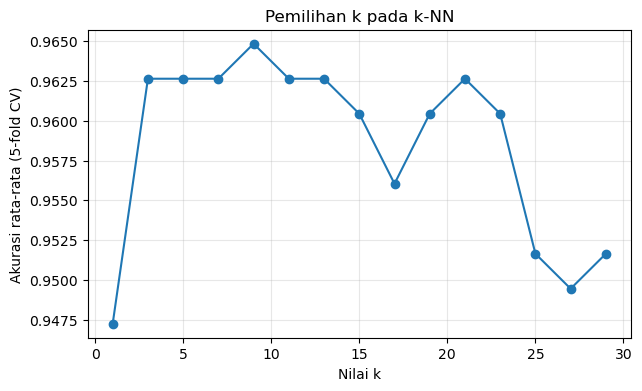

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks = range(1, 31, 2)
skor = []
for k in ks:
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    skor.append(cross_val_score(model, Xb_train, yb_train, cv=cv, scoring="accuracy").mean())

k_terbaik = list(ks)[int(np.argmax(skor))]
print("k terbaik:", k_terbaik, "| akurasi CV:", round(max(skor), 4))

plt.figure(figsize=(7,4))
plt.plot(list(ks), skor, marker="o")
plt.xlabel("Nilai k"); plt.ylabel("Akurasi rata-rata (5-fold CV)")
plt.title("Pemilihan k pada k-NN"); plt.grid(alpha=.3); plt.show()

### Langkah 7: membandingkan kedua model

Naive Bayes     F1-CV = 0.953 +/- 0.019 | Akurasi uji = 0.939
k-NN (k=9)      F1-CV = 0.972 +/- 0.011 | Akurasi uji = 0.974


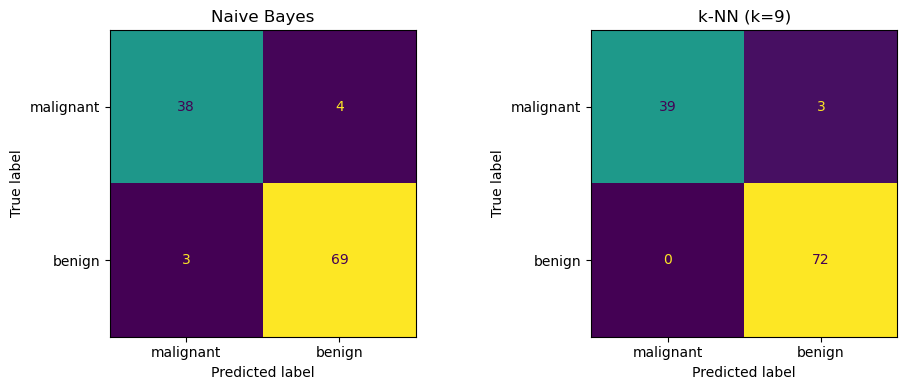

In [17]:
final = {
    "Naive Bayes": GaussianNB(),
    f"k-NN (k={k_terbaik})": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k_terbaik)),
}
for nama, model in final.items():
    f1 = cross_val_score(model, Xb_train, yb_train, cv=cv, scoring="f1")
    model.fit(Xb_train, yb_train)
    acc = accuracy_score(yb_test, model.predict(Xb_test))
    print(f"{nama:15s} F1-CV = {f1.mean():.3f} +/- {f1.std():.3f} | Akurasi uji = {acc:.3f}")

fig, ax = plt.subplots(1, 2, figsize=(10,4))
for a, (nama, model) in zip(ax, final.items()):
    ConfusionMatrixDisplay.from_estimator(model, Xb_test, yb_test,
        display_labels=data.target_names, ax=a, colorbar=False)
    a.set_title(nama)
plt.tight_layout(); plt.show()

# Tugas Terbimbing

### Tugas Terbimbing 2: k-NN dengan `weights="distance"` dan `metric="manhattan"`

In [18]:
varian = {
    f"k-NN standar (k={k_terbaik})": dict(n_neighbors=k_terbaik),
    f"k-NN distance (k={k_terbaik})": dict(n_neighbors=k_terbaik, weights="distance"),
    f"k-NN manhattan (k={k_terbaik})": dict(n_neighbors=k_terbaik, metric="manhattan"),
    f"k-NN distance+manhattan (k={k_terbaik})": dict(n_neighbors=k_terbaik, weights="distance", metric="manhattan"),
}
baris = []
for nama, par in varian.items():
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(**par))
    f1 = cross_val_score(model, Xb_train, yb_train, cv=cv, scoring="f1")
    acc = accuracy_score(yb_test, model.fit(Xb_train, yb_train).predict(Xb_test))
    baris.append({"Model": nama, "F1-CV (mean)": round(f1.mean(), 4), "F1-CV (std)": round(f1.std(), 4), "Akurasi uji": round(acc, 4)})
pd.DataFrame(baris)

,Model,F1-CV (mean),F1-CV (std),Akurasi uji
0,k-NN standar (k=9),0.9724,0.0114,0.9737
1,k-NN distance (k=9),0.9724,0.0114,0.9737
2,k-NN manhattan (k=9),0.9689,0.0178,0.9737
3,k-NN distance+manhattan (k=9),0.9689,0.0178,0.9737


*Tulis analisis di sini: apakah `weights="distance"` atau jarak Manhattan menaikkan F1-CV dibanding k-NN standar? Apakah selisihnya lebih besar daripada simpangan bakunya?*

### Tugas Terbimbing 3: precision, recall, F1 kelas malignant (k-NN terbaik) secara manual

In [19]:
model_knn = final[f"k-NN (k={k_terbaik})"]
cm = confusion_matrix(yb_test, model_knn.predict(Xb_test))   # baris = aktual, kolom = prediksi; urutan: 0 malignant, 1 benign
print(cm)

TP = cm[0, 0]      # malignant diprediksi malignant
FN = cm[0, 1]      # malignant diprediksi benign (berbahaya)
FP = cm[1, 0]      # benign diprediksi malignant
precision = TP / (TP + FP)
recall = TP / (TP + FN)
f1 = 2 * precision * recall / (precision + recall)
print(f"Manual    : precision={precision:.3f} recall={recall:.3f} F1={f1:.3f}")
print()
print(classification_report(yb_test, model_knn.predict(Xb_test), target_names=data.target_names, digits=3))

[[39  3]
 [ 0 72]]
Manual    : precision=1.000 recall=0.929 F1=0.963

              precision    recall  f1-score   support

   malignant      1.000     0.929     0.963        42
      benign      0.960     1.000     0.980        72

    accuracy                          0.974       114
   macro avg      0.980     0.964     0.971       114
weighted avg      0.975     0.974     0.973       114



### Tugas Terbimbing 4: rekomendasi model dari sudut pandang medis

In [20]:
for nama, model in final.items():
    cm_ = confusion_matrix(yb_test, model.predict(Xb_test))
    print(f"{nama:15s} false negative (ganas diprediksi jinak) = {cm_[0,1]} | recall malignant = {cm_[0,0]/cm_[0].sum():.3f}")

Naive Bayes     false negative (ganas diprediksi jinak) = 4 | recall malignant = 0.905
k-NN (k=9)      false negative (ganas diprediksi jinak) = 3 | recall malignant = 0.929


*Tulis rekomendasi di sini: model dengan false negative paling sedikit lebih aman untuk skrining. Sebutkan jumlah false negative kedua model dan alasannya.*

# BAGIAN 4. Tugas Mandiri: Prediksi Status Akademik Mahasiswa

**Sumber dataset (Kaggle):** https://www.kaggle.com/datasets/einherjar3451234123/prediksi-status-akademik-mahasiswa
(500 mahasiswa; atribut kehadiran, partisipasi diskusi, nilai tugas, aktivitas e-learning, IPK; target status akademik Lulus / Tidak).

**Cara memuat data di Google Colab:**
1. Unduh dataset dari Kaggle (perlu login), hasilnya berupa file `Dataset_Mahasiswa_Kehadiran_Aktivitas_IPK.xlsx`.
2. Di Colab, buka panel **Files** (ikon folder di kiri) dan unggah file tersebut.
3. Jalankan sel di bawah. Kalau nama file berbeda, ubah variabel `FILE`.

Kode di bawah mendeteksi kolom target dan kolom pengenal secara otomatis. **Periksa hasil deteksinya**, dan isi `TARGET` / `KELAS_RISIKO` secara manual jika salah.

## 4.1 Eksplorasi data

In [21]:
FILE = "Dataset_Mahasiswa_Kehadiran_Aktivitas_IPK.xlsx"

if not os.path.exists(FILE):
    ada = glob.glob("*.xlsx") + glob.glob("*.csv")
    raise FileNotFoundError(f"File '{FILE}' tidak ditemukan. File yang ada di folder kerja: {ada}. Unggah dataset atau ubah nilai FILE.")

df_raw = pd.read_excel(FILE) if FILE.endswith((".xlsx", ".xls")) else pd.read_csv(FILE)
print("Jumlah baris, kolom :", df_raw.shape)
print("\nTipe data dan nilai kosong:")
df_raw.info()
df_raw.head()

Jumlah baris, kolom : (500, 10)

Tipe data dan nilai kosong:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Nama                         500 non-null    object 
 1   Jenis Kelamin                500 non-null    object 
 2   Umur                         500 non-null    int64  
 3   Status Menikah               500 non-null    object 
 4   Kehadiran (%)                500 non-null    int64  
 5   Partisipasi Diskusi (skor)   500 non-null    int64  
 6   Nilai Tugas (rata-rata)      500 non-null    int64  
 7   Aktivitas E-Learning (skor)  500 non-null    int64  
 8   IPK                          500 non-null    float64
 9   Status Akademik              500 non-null    object 
dtypes: float64(1), int64(5), object(4)
memory usage: 39.2+ KB


,Nama,Jenis Kelamin,Umur,Status Menikah,Kehadiran (%),Partisipasi Diskusi (skor),Nilai Tugas (rata-rata),Aktivitas E-Learning (skor),IPK,Status Akademik
0,Kiki Ananda,Laki-laki,20,Belum Menikah,73,99,91,88,3.77,Lulus
1,Putri Fauzi,Laki-laki,21,Belum Menikah,42,83,53,64,3.55,Lulus
2,Mira Hidayat,Laki-laki,25,Belum Menikah,71,61,87,54,2.73,Lulus
3,Mira Ananda,Laki-laki,23,Belum Menikah,44,88,62,81,3.59,Tidak
4,Mira Septiani,Laki-laki,21,Menikah,54,92,67,64,3.02,Lulus


In [22]:
print("Statistik deskriptif:")
display(df_raw.describe(include="all").round(2))
print("\nMissing value per kolom:\n", df_raw.isnull().sum())
print("\nJumlah baris duplikat:", df_raw.duplicated().sum())

Statistik deskriptif:


,Nama,Jenis Kelamin,Umur,Status Menikah,Kehadiran (%),Partisipasi Diskusi (skor),Nilai Tugas (rata-rata),Aktivitas E-Learning (skor),IPK,Status Akademik
count,500,500,500.00,500,500.00,500.00,500.00,500.00,500.00,500
unique,278,2,NaN,2,NaN,NaN,NaN,NaN,NaN,2
top,Nina Ananda,Laki-laki,NaN,Belum Menikah,NaN,NaN,NaN,NaN,NaN,Lulus
freq,6,253,NaN,446,NaN,NaN,NaN,NaN,NaN,270
mean,NaN,NaN,21.54,NaN,69.43,69.62,70.18,69.48,2.81,NaN
std,NaN,NaN,2.27,NaN,17.89,17.34,17.31,17.85,0.72,NaN
min,NaN,NaN,18.00,NaN,40.00,40.00,40.00,40.00,1.50,NaN
25%,NaN,NaN,20.00,NaN,54.00,55.00,55.00,54.00,2.18,NaN
50%,NaN,NaN,22.00,NaN,69.00,69.50,69.00,69.50,2.82,NaN
75%,NaN,NaN,23.00,NaN,85.00,84.00,85.00,85.00,3.42,NaN



Missing value per kolom:
 Nama                           0
Jenis Kelamin                  0
Umur                           0
Status Menikah                 0
Kehadiran (%)                  0
Partisipasi Diskusi (skor)     0
Nilai Tugas (rata-rata)        0
Aktivitas E-Learning (skor)    0
IPK                            0
Status Akademik                0
dtype: int64

Jumlah baris duplikat: 0


## 4.2 Menentukan kolom target dan distribusi kelas

Kolom target : Status Akademik
Status Akademik
Lulus    270
Tidak    230
Name: count, dtype: int64
Status Akademik
Lulus    54.0 %
Tidak    46.0 %
Name: count, dtype: object


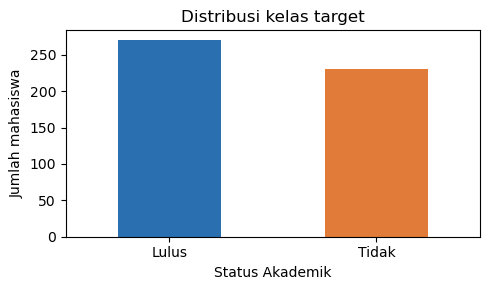

In [23]:
TARGET = None        # isi manual jika deteksi otomatis salah, contoh: "Status_Akademik"
KELAS_RISIKO = None  # label kelas yang dianggap berisiko, contoh: "Tidak"

if TARGET is None:
    kandidat = [c for c in df_raw.columns
                if df_raw[c].nunique() <= 5 and (df_raw[c].dtype == "object" or "status" in str(c).lower())]
    TARGET = kandidat[-1] if kandidat else df_raw.columns[-1]
print("Kolom target :", TARGET)

dist = df_raw[TARGET].value_counts(dropna=False)
print(dist)
print((dist / len(df_raw) * 100).round(1).astype(str) + " %")

dist.plot(kind="bar", color=["#2a6fb0", "#e07b39", "#7a7a7a"][:len(dist)], rot=0, figsize=(5, 3))
plt.title("Distribusi kelas target"); plt.ylabel("Jumlah mahasiswa"); plt.tight_layout(); plt.show()

## 4.3 Praproses

In [24]:
df = df_raw.dropna(subset=[TARGET]).copy()          # baris tanpa label tidak bisa dipakai

# buang kolom pengenal (id, nim, nama, atau teks dengan nilai hampir unik)
id_cols = [c for c in df.columns if c != TARGET and (
    str(c).strip().lower() in ("no", "id", "nim", "nama", "name")
    or (df[c].dtype == "object" and df[c].nunique() > 0.5 * len(df)))]
print("Kolom pengenal yang dibuang:", id_cols)

fitur_df = df.drop(columns=[TARGET] + id_cols)
kat_cols = fitur_df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Fitur kategorikal (di-encode):", kat_cols)
print("Fitur numerik:", [c for c in fitur_df.columns if c not in kat_cols])

X_m = pd.get_dummies(fitur_df, columns=kat_cols, drop_first=True).astype(float)   # encoding atribut kategorikal
le = LabelEncoder()
y_m = le.fit_transform(df[TARGET].astype(str))
kelas = list(le.classes_)
print("\nEncoding target:", {k: int(i) for i, k in enumerate(kelas)})

# kelas "berisiko" = kelas yang ingin kita deteksi (default: yang mengandung 'tidak'/'gagal'/'drop', atau kelas minoritas)
if KELAS_RISIKO is None:
    cocok = [k for k in kelas if any(s in k.lower() for s in ("tidak", "gagal", "drop", "terlambat"))]
    KELAS_RISIKO = cocok[0] if cocok else df[TARGET].astype(str).value_counts().idxmin()
idx_risiko = kelas.index(str(KELAS_RISIKO))
print("Kelas berisiko yang difokuskan:", KELAS_RISIKO, "(kode", idx_risiko, ")")
print("Ukuran matriks fitur:", X_m.shape)

Kolom pengenal yang dibuang: ['Nama']
Fitur kategorikal (di-encode): ['Jenis Kelamin', 'Status Menikah']
Fitur numerik: ['Umur', 'Kehadiran (%)', 'Partisipasi Diskusi (skor)', 'Nilai Tugas (rata-rata)', 'Aktivitas E-Learning (skor)', 'IPK']

Encoding target: {'Lulus': 0, 'Tidak': 1}
Kelas berisiko yang difokuskan: Tidak (kode 1 )
Ukuran matriks fitur: (500, 8)


**Catatan praproses:** *missing value* ditangani dengan `SimpleImputer` (median) **di dalam pipeline**, sehingga nilai median hanya dihitung dari data latih (tidak ada data leakage). Normalisasi `StandardScaler` juga di dalam pipeline dan hanya dipakai untuk k-NN, sedangkan Naive Bayes tidak memerlukannya.

In [25]:
# Korelasi antar fitur: berkaitan dengan asumsi independensi Naive Bayes
print(X_m.corr().round(2))

X_m.assign(**{TARGET: df[TARGET].astype(str).values}).groupby(TARGET).mean().round(2).T

                             Umur  Kehadiran (%)  Partisipasi Diskusi (skor)  \
Umur                         1.00          -0.04                        0.01   
Kehadiran (%)               -0.04           1.00                       -0.06   
Partisipasi Diskusi (skor)   0.01          -0.06                        1.00   
Nilai Tugas (rata-rata)      0.04           0.05                        0.00   
Aktivitas E-Learning (skor)  0.08           0.03                       -0.08   
IPK                          0.06           0.06                        0.07   
Jenis Kelamin_Perempuan     -0.05           0.01                       -0.01   
Status Menikah_Menikah       0.02           0.05                        0.05   

                             Nilai Tugas (rata-rata)  \
Umur                                            0.04   
Kehadiran (%)                                   0.05   
Partisipasi Diskusi (skor)                      0.00   
Nilai Tugas (rata-rata)                         1.00   

Status Akademik,Lulus,Tidak
Umur,21.58,21.49
Kehadiran (%),72.95,65.30
Partisipasi Diskusi (skor),72.10,66.71
Nilai Tugas (rata-rata),74.39,65.24
Aktivitas E-Learning (skor),72.78,65.60
IPK,3.00,2.58
Jenis Kelamin_Perempuan,0.46,0.53
Status Menikah_Menikah,0.11,0.10


## 4.4 Pembagian data dan model

In [26]:
Xm_train, Xm_test, ym_train, ym_test = train_test_split(
    X_m, y_m, test_size=0.2, stratify=y_m, random_state=42)
print("Data latih:", Xm_train.shape, "| Data uji:", Xm_test.shape)

imp = SimpleImputer(strategy="median")
nb_m = make_pipeline(imp, GaussianNB())          # semua fitur numerik -> Gaussian Naive Bayes

# k-NN: bandingkan tanpa dan dengan scaling pada k = 5
knn_tanpa = make_pipeline(SimpleImputer(strategy="median"), KNeighborsClassifier(n_neighbors=5)).fit(Xm_train, ym_train)
knn_dengan = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=5)).fit(Xm_train, ym_train)
print("Akurasi k-NN (k=5) tanpa scaling :", round(accuracy_score(ym_test, knn_tanpa.predict(Xm_test)), 4))
print("Akurasi k-NN (k=5) dengan scaling:", round(accuracy_score(ym_test, knn_dengan.predict(Xm_test)), 4))

Data latih: (400, 8) | Data uji: (100, 8)
Akurasi k-NN (k=5) tanpa scaling : 0.66
Akurasi k-NN (k=5) dengan scaling: 0.66


### Memilih k terbaik dengan 5-fold cross-validation (hanya pada data latih)

k terbaik: 31 | akurasi CV: 0.6775


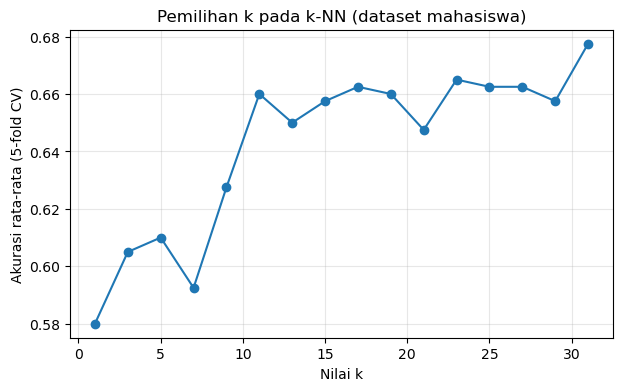

In [27]:
cv_m = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
ks_m = list(range(1, 32, 2))
skor_m = []
for k in ks_m:
    mdl = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    skor_m.append(cross_val_score(mdl, Xm_train, ym_train, cv=cv_m, scoring="accuracy").mean())
k_m = ks_m[int(np.argmax(skor_m))]
print("k terbaik:", k_m, "| akurasi CV:", round(max(skor_m), 4))

plt.figure(figsize=(7, 4))
plt.plot(ks_m, skor_m, marker="o")
plt.xlabel("Nilai k"); plt.ylabel("Akurasi rata-rata (5-fold CV)")
plt.title("Pemilihan k pada k-NN (dataset mahasiswa)"); plt.grid(alpha=.3); plt.show()

## 4.5 Evaluasi dan perbandingan model

In [28]:
model_set = {
    "Naive Bayes": make_pipeline(SimpleImputer(strategy="median"), GaussianNB()),
    f"k-NN (k={k_m})": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsClassifier(n_neighbors=k_m)),
}
f1_risiko = make_scorer(f1_score, pos_label=idx_risiko)

hasil, preds = [], {}
for nama, mdl in model_set.items():
    cv_f1 = cross_val_score(mdl, Xm_train, ym_train, cv=cv_m, scoring=f1_risiko)
    mdl.fit(Xm_train, ym_train)
    yp = mdl.predict(Xm_test); preds[nama] = yp
    cm_ = confusion_matrix(ym_test, yp, labels=range(len(kelas)))
    hasil.append({
        "Model": nama,
        "Akurasi uji": round(accuracy_score(ym_test, yp), 3),
        f"Precision {KELAS_RISIKO}": round(precision_score(ym_test, yp, pos_label=idx_risiko, zero_division=0), 3),
        f"Recall {KELAS_RISIKO}": round(recall_score(ym_test, yp, pos_label=idx_risiko, zero_division=0), 3),
        f"F1 {KELAS_RISIKO}": round(f1_score(ym_test, yp, pos_label=idx_risiko, zero_division=0), 3),
        f"F1-CV {KELAS_RISIKO}": f"{cv_f1.mean():.3f} +/- {cv_f1.std():.3f}",
        f"Salah ({KELAS_RISIKO} diprediksi lain)": int(cm_[idx_risiko].sum() - cm_[idx_risiko, idx_risiko]),
    })
tabel_hasil = pd.DataFrame(hasil)
tabel_hasil

,Model,Akurasi uji,Precision Tidak,Recall Tidak,F1 Tidak,F1-CV Tidak,Salah (Tidak diprediksi lain)
0,Naive Bayes,0.73,0.721,0.674,0.697,0.631 +/- 0.045,15
1,k-NN (k=31),0.72,0.705,0.674,0.689,0.631 +/- 0.044,15


===== Naive Bayes =====
              precision    recall  f1-score   support

       Lulus      0.737     0.778     0.757        54
       Tidak      0.721     0.674     0.697        46

    accuracy                          0.730       100
   macro avg      0.729     0.726     0.727       100
weighted avg      0.730     0.730     0.729       100

Confusion matrix (baris = aktual, kolom = prediksi):
 [[42 12]
 [15 31]] 

===== k-NN (k=31) =====
              precision    recall  f1-score   support

       Lulus      0.732     0.759     0.745        54
       Tidak      0.705     0.674     0.689        46

    accuracy                          0.720       100
   macro avg      0.718     0.717     0.717       100
weighted avg      0.719     0.720     0.719       100

Confusion matrix (baris = aktual, kolom = prediksi):
 [[41 13]
 [15 31]] 



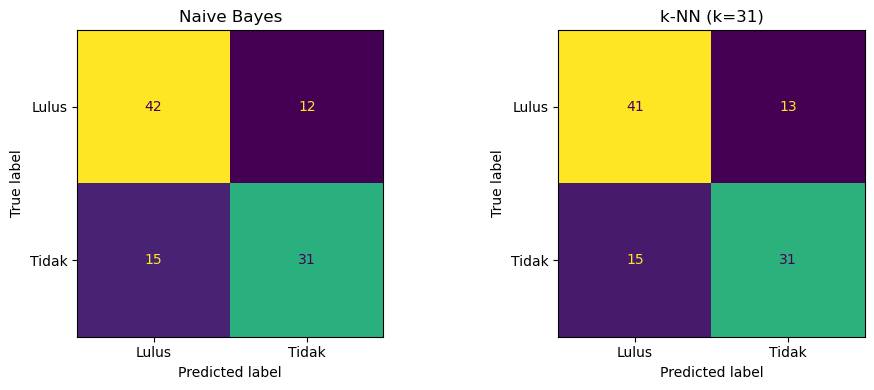

In [29]:
for nama, yp in preds.items():
    print("=====", nama, "=====")
    print(classification_report(ym_test, yp, target_names=kelas, digits=3, zero_division=0))
    print("Confusion matrix (baris = aktual, kolom = prediksi):\n", confusion_matrix(ym_test, yp), "\n")

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (nama, mdl) in zip(ax, model_set.items()):
    ConfusionMatrixDisplay.from_estimator(mdl, Xm_test, ym_test, display_labels=kelas, ax=a, colorbar=False)
    a.set_title(nama)
plt.tight_layout(); plt.savefig("tugas_mandiri_confusion_matrix.png", dpi=150); plt.show()